# Phase 2: Data Acquisition & Setup (Track B)
**Group F26-16** | NASA C-MAPSS turbofan dataset, sub-dataset FD001 | RUL Prediction with Uncertainty Quantification

Steps: mount Drive and extract the data, load the files, label RUL, remove constant features, cap RUL and scale, build sliding windows, save arrays, and run a brief EDA.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os, glob

DATA_DIR = "/content/drive/MyDrive/RUL_project/data"
zip_path = glob.glob(f"{DATA_DIR}/*.zip")[0]
print("Found zip:", zip_path)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(DATA_DIR)

print(os.listdir(DATA_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found zip: /content/drive/MyDrive/RUL_project/data/6.+Turbofan+Engine+Degradation+Simulation+Data+Set (1).zip
['6.+Turbofan+Engine+Degradation+Simulation+Data+Set (1).zip', '6. Turbofan Engine Degradation Simulation Data Set']


In [5]:
import shutil

# move all .txt files anywhere under DATA_DIR to the top level
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        if f.endswith('.txt') and root != DATA_DIR:
            shutil.move(os.path.join(root, f), os.path.join(DATA_DIR, f))

# extract any nested zip (e.g. CMAPSSData.zip) if present
nested_zips = glob.glob(f"{DATA_DIR}/**/*.zip", recursive=True)
for nz in nested_zips:
    with zipfile.ZipFile(nz, 'r') as z:
        z.extractall(DATA_DIR)

# re-run the move in case the nested zip added more .txt files
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        if f.endswith('.txt') and root != DATA_DIR:
            shutil.move(os.path.join(root, f), os.path.join(DATA_DIR, f))

txt_files = sorted([f for f in os.listdir(DATA_DIR) if f.endswith('.txt')])
print(txt_files)

['RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'readme.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']


In [7]:
import pandas as pd
DATASET = "FD001"

cols = ['unit', 'cycle'] + [f'op{i}' for i in range(1, 4)] + [f's{i}' for i in range(1, 22)]

train = pd.read_csv(f"{DATA_DIR}/train_{DATASET}.txt", sep=r'\s+', header=None, names=cols)
test  = pd.read_csv(f"{DATA_DIR}/test_{DATASET}.txt",  sep=r'\s+', header=None, names=cols)
rul_test = pd.read_csv(f"{DATA_DIR}/RUL_{DATASET}.txt", header=None, names=['RUL'])

train['RUL'] = train.groupby('unit')['cycle'].transform('max') - train['cycle']

print(train.shape, test.shape, rul_test.shape)
print("Train engines:", train['unit'].nunique(), "| Test engines:", test['unit'].nunique())
train.head()

(20631, 27) (13096, 26) (100, 1)
Train engines: 100 | Test engines: 100


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


 ## Drop constant/uninformative sensors


In [8]:
sensor_cols = [c for c in train.columns if c.startswith('s')]
stds = train[sensor_cols].std()
print(stds.sort_values())

constant_sensors = stds[stds < 0.0001].index.tolist()
print("\nDropping:", constant_sensors)

train_clean = train.drop(columns=constant_sensors)
test_clean  = test.drop(columns=constant_sensors)
print(train_clean.shape, test_clean.shape)

s19    0.000000e+00
s18    0.000000e+00
s16    1.556432e-14
s10    4.660829e-13
s5     3.394700e-12
s1     6.537152e-11
s6     1.388985e-03
s15    3.750504e-02
s8     7.098548e-02
s13    7.191892e-02
s21    1.082509e-01
s20    1.807464e-01
s11    2.670874e-01
s2     5.000533e-01
s12    7.375534e-01
s7     8.850923e-01
s17    1.548763e+00
s3     6.131150e+00
s4     9.000605e+00
s14    1.907618e+01
s9     2.208288e+01
dtype: float64

Dropping: ['s1', 's5', 's10', 's16', 's18', 's19']
(20631, 21) (13096, 20)


## Cap RUL and scale features

In [9]:
from sklearn.preprocessing import MinMaxScaler

RUL_CAP = 125
train_clean['RUL'] = train_clean['RUL'].clip(upper=RUL_CAP)

feature_cols = [c for c in train_clean.columns if c.startswith('op') or c.startswith('s')]
scaler = MinMaxScaler()
train_clean[feature_cols] = scaler.fit_transform(train_clean[feature_cols])
test_clean[feature_cols]  = scaler.transform(test_clean[feature_cols])

train_clean.describe()

,unit,cycle,op1,op2,op3,s2,s3,s4,s6,s7,...,s9,s11,s12,s13,s14,s15,s17,s20,s21,RUL
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,...,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000
mean,51.506568,108.807862,0.499490,0.501959,0.0,0.443052,0.424746,0.450435,0.980321,0.566459,...,0.195248,0.411410,0.580697,0.317871,0.226095,0.451118,0.434221,0.524241,0.546127,86.829286
std,29.227633,68.880990,0.125708,0.244218,0.0,0.150618,0.133664,0.151935,0.138898,0.142527,...,0.099089,0.158981,0.157261,0.105763,0.098442,0.144306,0.129064,0.140114,0.149476,41.673699
min,1.000000,1.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.000000,52.000000,0.413793,0.333333,0.0,0.335843,0.331807,0.339467,1.000000,0.476651,...,0.140761,0.297619,0.484009,0.235294,0.171870,0.346287,0.333333,0.434109,0.452361,51.000000
50%,52.000000,104.000000,0.500000,0.500000,0.0,0.430723,0.415522,0.435348,1.000000,0.578100,...,0.174684,0.392857,0.594883,0.308824,0.209516,0.438630,0.416667,0.534884,0.557443,103.000000
75%,77.000000,156.000000,0.586207,0.750000,0.0,0.539157,0.508829,0.545324,1.000000,0.669887,...,0.213991,0.505952,0.695096,0.382353,0.249613,0.541362,0.500000,0.627907,0.652582,125.000000
max,100.000000,362.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,125.000000


## Dropping constant operating settings

In [10]:
# also drop constant operating-setting columns
op_cols = ['op1', 'op2', 'op3']
op_stds = train_clean[op_cols].std()
constant_ops = op_stds[op_stds < 0.0001].index.tolist()
print("Dropping constant op columns:", constant_ops)

train_clean = train_clean.drop(columns=constant_ops)
test_clean  = test_clean.drop(columns=constant_ops)

Dropping constant op columns: ['op3']


## Sliding windows


In [13]:
import numpy as np
WINDOW = 30

feature_cols = [c for c in train_clean.columns if c.startswith('op') or c.startswith('s')]
print("Features used:", feature_cols)

def make_windows(df, feature_cols, window=WINDOW, label_col='RUL'):
    X, y = [], []
    for uid, g in df.groupby('unit'):
        g = g.reset_index(drop=True)
        if len(g) < window:
            continue
        for i in range(len(g) - window + 1):
            X.append(g.loc[i:i+window-1, feature_cols].values)
            y.append(g.loc[i+window-1, label_col])
    return np.array(X), np.array(y)

X_train, y_train = make_windows(train_clean, feature_cols)
print(X_train.shape, y_train.shape)

Features used: ['op1', 'op2', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
(17731, 30, 17) (17731,)


In [14]:
np.save(f"{DATA_DIR}/X_train_{DATASET}.npy", X_train)
np.save(f"{DATA_DIR}/y_train_{DATASET}.npy", y_train)
print("Saved.")

Saved.


## Brief EDA


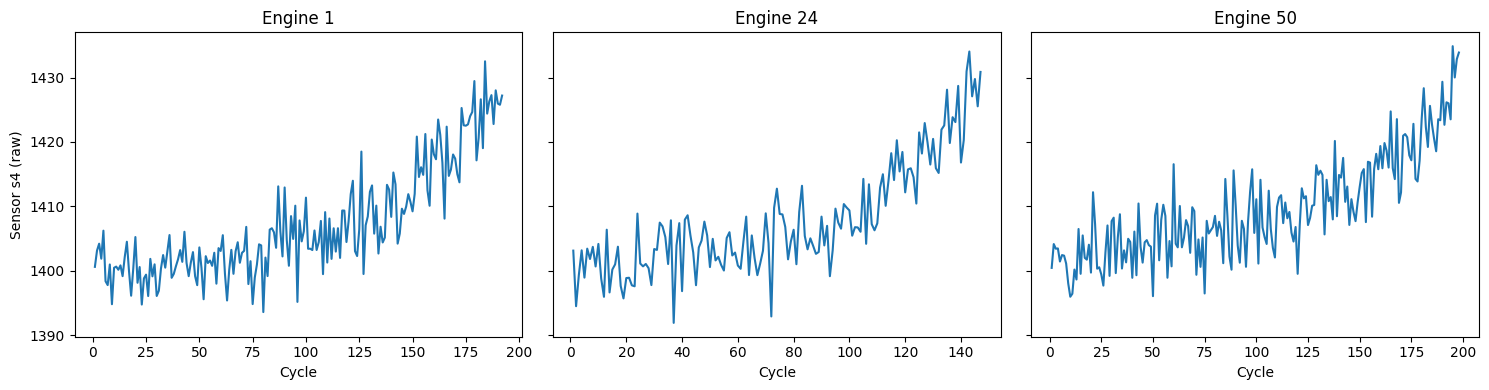

In [15]:
import matplotlib.pyplot as plt

sample_engines = [1, 24, 50]
fig, axes = plt.subplots(1, len(sample_engines), figsize=(15, 4), sharey=True)
for ax, uid in zip(axes, sample_engines):
    g = train[train['unit'] == uid]
    ax.plot(g['cycle'], g['s4'])  # s4 is a clearly degrading sensor in FD001
    ax.set_title(f"Engine {uid}")
    ax.set_xlabel("Cycle")
axes[0].set_ylabel("Sensor s4 (raw)")
plt.tight_layout()
plt.show()

**Figure 1: sensor s4 vs cycle (engines 1, 24, 50).** s4 stays flat and noisy early in life and rises from about 1400 to about 1430-1435 near failure for all three engines. This shows that the sensors carry a degradation signal that models can learn.

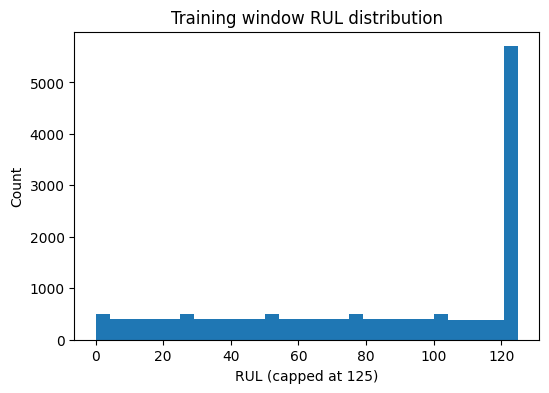

In [16]:
plt.figure(figsize=(6,4))
plt.hist(y_train, bins=30)
plt.xlabel("RUL (capped at 125)")
plt.ylabel("Count")
plt.title("Training window RUL distribution")
plt.show()

**Figure 2: distribution of RUL labels.** RUL values from 0 to about 120 are spread fairly evenly, and there is a large spike at 125 caused by the RUL cap. This is expected; we will check later that the model is not biased toward predicting 125.

## Summary and next steps
Final training set: `X_train` (17731, 30, 17) and `y_train` (17731,), saved as `.npy` files. `test_clean` is already scaled with the training scaler; it will be windowed and evaluated against `RUL_FD001.txt` in the modelling phase.